# Activity 2 — Workbench check

This notebook confirms that the `ti2006b-workbench` conda environment is selected as the **kernel** in VS Code and that pandas and matplotlib work.

It reuses the classroom dataset from Activity 2.6 (`pokemon_go_kanto_candidates.csv`).

In [1]:
import sys
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import pandas as pd

# The kernel name should point to the ti2006b-workbench environment.
print('Environment:', Path(sys.prefix).name)
print('Python', sys.version.split()[0], '| pandas', pd.__version__, '| matplotlib', matplotlib.__version__)

Environment: ti2006b-workbench
Python 3.12.16 | pandas 3.1.0 | matplotlib 3.11.2


In [2]:
# Find the data file whether the notebook runs from the repo root or this folder.
relative = Path('activities/2.6-github-project-home/data/pokemon_go_kanto_candidates.csv')
candidates = [Path.cwd() / relative, Path.cwd().parents[1] / relative]
data_file = next(p for p in candidates if p.exists())

df = pd.read_csv(data_file)
df.head()

,pokedex_id,pokemon,type_1,type_2,great_league_eligible,attack_index,bulk_index,move_coverage_index,meta_signal_index,source_note
0,1,Venusaur,Grass,Poison,True,67,78,83,78,classroom proxy
1,3,Charizard,Fire,Flying,True,82,55,86,84,classroom proxy
2,6,Blastoise,Water,NaN,True,65,82,76,75,classroom proxy
3,15,Beedrill,Bug,Poison,True,72,48,74,63,classroom proxy
4,18,Pidgeot,Normal,Flying,True,61,76,81,70,classroom proxy


In [3]:
features = ['attack_index', 'bulk_index', 'move_coverage_index', 'meta_signal_index']
df['mean_score'] = df[features].mean(axis=1).round(1)
df.sort_values('mean_score', ascending=False).head(5)[['pokemon', 'type_1', 'mean_score']]

,pokemon,type_1,mean_score
14,Snorlax,Normal,85.5
13,Lapras,Water,84.8
10,Poliwrath,Water,82.8
8,Nidoqueen,Poison,81.0
12,Slowbro,Water,79.2


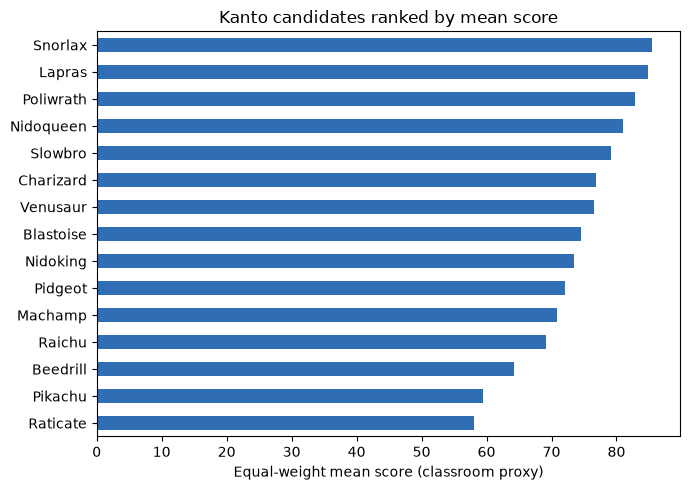

In [4]:
ax = df.sort_values('mean_score').plot.barh(x='pokemon', y='mean_score', legend=False,
                                             figsize=(7, 5), color='#2f6db5')
ax.set_xlabel('Equal-weight mean score (classroom proxy)')
ax.set_ylabel('')
ax.set_title('Kanto candidates ranked by mean score')
plt.tight_layout()
plt.show()

If every cell ran without errors, the interpreter and the notebook kernel are both using `ti2006b-workbench`.